## Lane line amplification 

Trying to test whether we can gather better SSD information by minimizing the contribution of concrete-to-concrete
- By embellishing the lane line through gradient comparisons

In [ ]:
from groundNAV_agent import gNAV_agent
# from microp_distb import microp_distb
# from distb_plt_utils import microp_distb_plotter

import pycolmap

import numpy as np
import open3d as o3d
import copy
import pickle
import cv2
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree

# SAVE YOUR WORK
%load_ext autoreload
%autoreload 2
%autosave 180

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


Autosaving every 180 seconds


In [3]:
# Upload dataset inputs

# Colmap data
colm_fn = "../datasets/KBCB_colm/"

# Local test images 
# im_local = '../datasets/KBCB_test_images/' # With 10 local images 
# New local test image - frame 28599 NOT in COLMAP 
im_local = '../datasets/LSA_test_images/'


# Satellite reference image
# sat_ref = "../datasets/KBCB_satellite/KBCB_partial.jpg" # Public google earth satellite imagery
sat_ref = "../datasets/KBCB_satellite/KBCB_partial_LSA.png" # Public google earth satellite imagery



# Ground truth solutions
ind_params_KBCB = np.load("ind_params_KBCB_FULL.npy")

In [4]:
# Pose id for new frame
id_LSA = 121
# Starting scale and yaw from last KBCB ground truth solution
scale0, yaw0 = ind_params_KBCB[-1][0], ind_params_KBCB[-1][1]

# Candidate locations - satellite PIXEL coords (x, y) TODO: pick from KBCB_partial_LSA.png
sat_shift = np.array([700, 600]) # Same shift as sat_im_init
cands_px = {'A': (1000, 900),
            'B': (1500, 900)}
cand_params = {k: np.array([[scale0, yaw0, px - sat_shift[0], py - sat_shift[1]]])
               for k, (px, py) in cands_px.items()}

# Start with candidate A
ind_params = cand_params['A']

In [5]:
# Create class
gnav = gNAV_agent(colm_fn, im_local, sat_ref, ind_params)

# Borrow pose (image_parsing leaves unmatched ids at 0)
print("Parsed im_ids:", gnav.im_ids)
gnav.im_ids[0] = id_LSA
print("Borrowed:", gnav.im_ids, gnav.images_c[id_LSA].name)

Parsed im_ids: [0]
Borrowed: [121] frame_26999.jpg


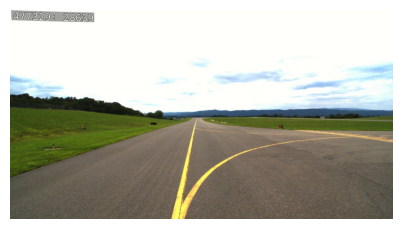

In [6]:
# VISUALIZER
gnav.visualize_local_ims()

In [7]:
# Using pre_calculated ground plane points - read explanation below 
pts_gnd_idx = np.load('../datasets/KBCB_params/ground_pts_idxs.npy')
gnav.pts_gnd_idx = pts_gnd_idx
# Run the ground plane extractor for visualization purposes 
pts_gnd_idx_test = gnav.get_gnd_pts() 
# # Visualize ground plane points 
# gnav.visualize_ground_pts(pts_gnd_idx_test) # UNCOMMENT for visualizations 

### Set ref frame

In [8]:
# Gather reference frame
tform_ref_frame = gnav.set_ref_frame() 
tform_ref_frame_pts = gnav.inv_homog_transform(tform_ref_frame)
gnav.tform_ref_frame_pts = tform_ref_frame_pts
print("\nReference frame transformation\n", tform_ref_frame_pts)

# Transform all points to the new coordinate system - for visual check 
tform_ref_frame_inv = gnav.inv_homog_transform(tform_ref_frame)
origin_ref, scene_pts_ref, scene_vec_ref = gnav.unit_vec_tform(gnav.scene_pts, gnav.origin_w, tform_ref_frame_inv)
gnav.scene_pts_ref = scene_pts_ref

Gravity vector 
 [-0.00516537  0.99923869  0.03866977]

Height h_0 =  0.09328363092429819

Reference frame transformation
 [[ 0.61692741  0.03361836 -0.7863017   0.20779018]
 [-0.7870031   0.01979491 -0.6166314  -0.15853791]
 [-0.00516537  0.99923869  0.03866977  0.90871723]
 [ 0.          0.          0.          1.        ]]


In [9]:
# Visualizer
gnav.visualize_ref_frame(scene_pts_ref)
# Optionally, view the direction of the gravity vector
# gnav.visualize_grav_vec()

878 1600 ytot xtot


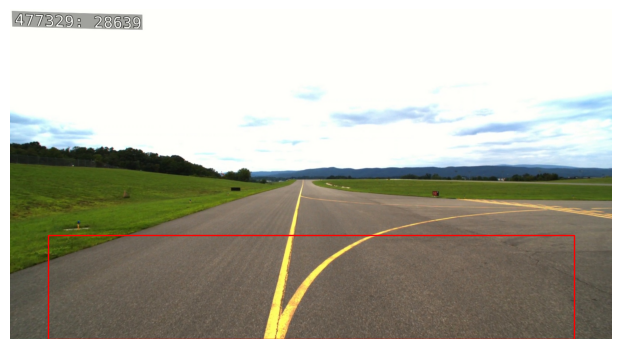

In [10]:
%matplotlib qt
# Prune points and create mask
# pts = gnav.prune_satellite_image()

# AUTOMATED PATCH EXTRACTION 
%matplotlib inline
# Initial size
params_tot = gnav.get_initial_params()
# Grab points and plot
gnav.grab_image_pts_tot(params_tot)
gnav.plot_gnd_pts()

In [ ]:
# ROI PROJECTION FUNCTION 

def project_roi(gnav, roi):
    """
    Grab ROI pixels and project onto the ground plane in the ref frame 
    Input: roi (x, y, width, height)
    """
    gnav.grab_image_pts_tot(np.array([roi]))

    for i in range(gnav.im_num):
        # Unit vectors in camera coords
        pts_vec_c, pts_rgb_gnd = gnav.unit_vec_c(i)
        gnav.im_mosaic[i] = {'rgbc': pts_rgb_gnd}

        # Camera to world transform
        homog_w2c, homog_c2w = gnav.get_pose_id(gnav.im_ids[i], i)

        # Transform to world coords and intersect with ground plane
        origin_c, pts_loc_w, pts_vec_w = gnav.unit_vec_tform(pts_vec_c, gnav.origin_w, homog_c2w)
        ranges, new_pts_w = gnav.pt_range(pts_vec_w, homog_c2w, origin_c, i)

        # Transfer points to reference frame
        __, new_pts_r, pts_vec_r = gnav.unit_vec_tform(new_pts_w, gnav.origin_w, gnav.tform_ref_frame_pts)

        # Store points and grayscale colors
        gnav.im_mosaic[i]['pts'] = new_pts_r
        gnav.im_mosaic[i]['color_g'] = gnav.conv_to_gray(gnav.im_mosaic[i]['rgbc'], i)

        # Image row of each point (same flattening order as pts) - for resolution check by row band
        gnav.im_mosaic[i]['rows'] = gnav.im_pts_2d[i]['pts'][..., 1].ravel()

        # Range check - r <= 0 means ray is at/above horizon
        r = gnav.im_pts_2d[i]['r']
        print(f"Image {i}: {r.size} pts, range min/max = {r.min():.3f}/{r.max():.3f}, "
              f"max/min = {r.max()/r.min():.1f}, r <= 0: {(r <= 0).sum()}")

In [12]:
# ROIs (x, y, width, height) and projection
H, W = gnav.images_dict[0].shape[:2]
rois = {'base': (100, 600, W - 200, H - 600),
        'clean': (50, 550, W - 100, H - 550),
        'extended': (50, 475, W - 100, H - 475)}
roi_key = 'clean'
project_roi(gnav, rois[roi_key])

# Hand-aligned locations (from lsa_example): scale, rotation (deg), x, y
locs = {'loc1': (140, 336, 322, 320), 'loc2': (110, 336, 1420, 885)} #140, 335, 1565, 952)}
n_ssd = 5

# Baseline: intensity SSD (mean SD = SSD / sat px count at zero shift)
ssds_int, n_sat = {}, {}
for key, (scale, rot_deg, x, y) in locs.items():
    gnav.implement_guess_ind(np.array([[scale, np.deg2rad(rot_deg), x, y]]))
    ssds_int[key] = gnav.ssd_nxn(n_ssd, 0)
    n_sat[key] = len(gnav.get_inside_sat_pts(0, 0, 0)[0])
    i, j = np.unravel_index(np.argmin(ssds_int[key]), ssds_int[key].shape)
    print(f"{key}: min mean SD = {ssds_int[key][i, j]/n_sat[key]:.4f} at shift ({i-n_ssd}, {j-n_ssd})")


Image 0: 492000 pts, range min/max = 0.276/1.189, max/min = 4.3, r <= 0: 0
Number of points used for image 0:  (9618,)
loc1: min mean SD = 0.0049 at shift (-4, -1)
Number of points used for image 0:  (5939,)
loc2: min mean SD = 0.0061 at shift (-5, -3)


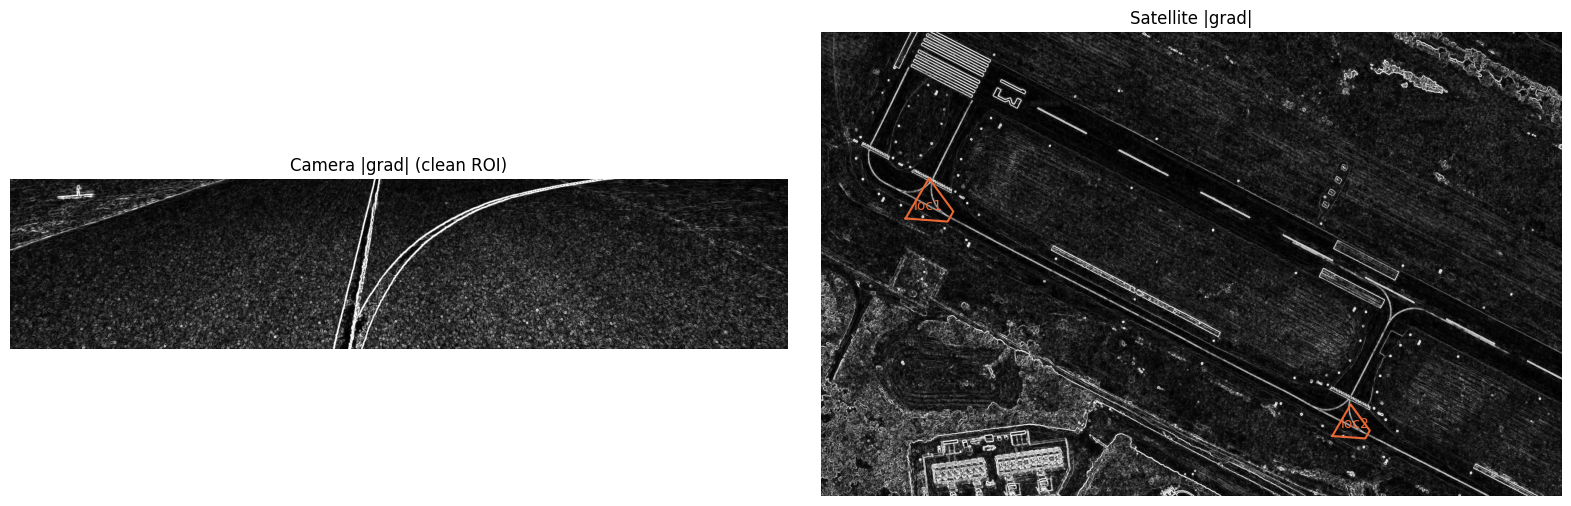

In [14]:
def grad_mag(gray):
    """
    Sobel gradient magnitude on a grayscale image (0-1)
    Output: |grad| per pixel, same shape as input
    """
    gx = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
    gy = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)
    return np.hypot(gx, gy)

# Camera: gradient on full image (no border effects at ROI edge), then crop to ROI
# Crop is row-major (h, w) - same order as im_mosaic pts
gray_cam = cv2.cvtColor(gnav.images_dict[0], cv2.COLOR_BGR2GRAY).astype(np.float64) / 255
x0, y0, w, h = rois[roi_key]
g_im = grad_mag(gray_cam)[y0:y0+h, x0:x0+w].ravel()

# Satellite: gradient on full sat image - ravel matches ref_pts order
g_sat = grad_mag(gnav.sat_ref.astype(np.float64) / 255).ravel()

# Normalize each to ~0-1 by its own 99th percentile (replaces bc_diff offset + clipping)
g_im = np.minimum(g_im / np.percentile(g_im, 99), 1)
g_sat = np.minimum(g_sat / np.percentile(g_sat, 99), 1)

# Visual check: lane lines should be the brightest features in both
sat_shift = np.array([700, 600])
fig, axs = plt.subplots(1, 2, figsize=(16, 5))
axs[0].imshow(g_im.reshape(h, w), cmap='gray')
axs[0].set_title(f'Camera |grad| ({roi_key} ROI)')
axs[1].imshow(g_sat.reshape(gnav.sat_ref.shape), cmap='gray')
for key, (scale, rot_deg, x, y) in locs.items():
    # Footprint outline from the projected ROI corners - (x, y) is only the shift, not where the image lands
    gnav.implement_guess_ind(np.array([[scale, np.deg2rad(rot_deg), x, y]]))
    pts = gnav.im_pts_best_guess[0]['pts'][:, :2] + sat_shift
    pts = pts[[0, w - 1, -1, -w, 0]] # Top-left, top-right, bottom-right, bottom-left, close
    axs[1].plot(pts[:, 0], pts[:, 1], color='#eb6834', lw=1.5)
    axs[1].annotate(key, pts[0], color='#eb6834', xytext=(6, 6), textcoords='offset points')
axs[1].set_title('Satellite |grad|')
for ax in axs:
    ax.axis('off')
plt.tight_layout()
plt.show()


loc1: min gradient mean SD = 0.0542 at shift (5, 5)
loc2: min gradient mean SD = 0.0506 at shift (5, 4)


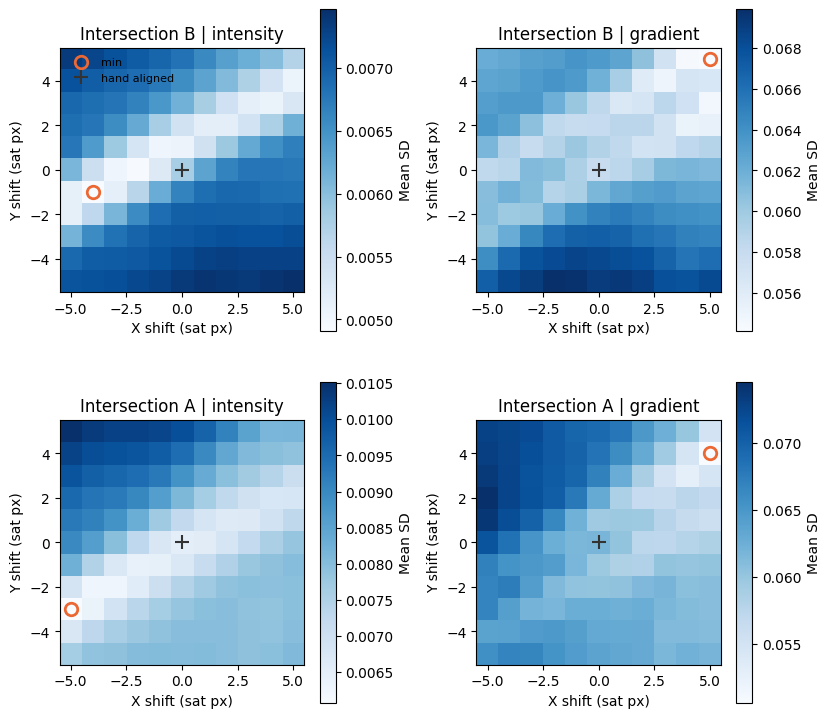

 intensity: sharpness loc1 = 0.274, loc2 = 0.234 | loc2/loc1 = 1.24
  gradient: sharpness loc1 = 0.128, loc2 = 0.194 | loc2/loc1 = 0.93


In [16]:
def ssd_grad(gnav, n, g_im, g_sat):
    """
    Gradient SSD: same footprint and nearest-neighbor matching as ssd_nxn, 
    but comparing gradient magnitudes instead of intensity (no bc_diff offset/clipping)
    Input: n shift amount, g_im (|grad| per projected image pt), g_sat (|grad| per ref_pts entry)
    Output: mean SD for each shift (exact sat px count per shift)
    """
    sat_w = gnav.sat_ref.shape[1]

    # Tree on unshifted image points - shifting image by +s is the same as querying sat pts at -s
    tree = cKDTree(gnav.im_pts_best_guess[0]['pts'][:, :2])

    msd = np.zeros((2*n+1, 2*n+1))
    for shiftx in range(-n, n+1):
        for shifty in range(-n, n+1):
            # Sat pixels inside shifted image footprint (same as ssd_nxn)
            inside_pts, __ = gnav.get_inside_sat_pts(0, shiftx, shifty)

            # Sat gradient: ref_pts coords back to sat pixel index (undo the [700, 600] shift)
            px = inside_pts[:, 0].astype(int) + sat_shift[0]
            py = inside_pts[:, 1].astype(int) + sat_shift[1]
            gs = g_sat[py * sat_w + px]

            # Image gradient at nearest projected image pixel
            __, idxs = tree.query(inside_pts[:, :2] - np.array([shiftx, shifty]), k=1)
            gi = g_im[idxs]

            msd[shiftx + n, shifty + n] = np.mean((gs - gi)**2)

    return msd


# Run at each location
msd_grad = {}
for key, (scale, rot_deg, x, y) in locs.items():
    gnav.implement_guess_ind(np.array([[scale, np.deg2rad(rot_deg), x, y]]))
    msd_grad[key] = ssd_grad(gnav, n_ssd, g_im, g_sat)
    i, j = np.unravel_index(np.argmin(msd_grad[key]), msd_grad[key].shape)
    print(f"{key}: min gradient mean SD = {msd_grad[key][i, j]:.4f} at shift ({i-n_ssd}, {j-n_ssd})")

# Heatmaps: rows = location, cols = intensity vs gradient (own color scale per panel - compare shapes)
panels = {'intensity': lambda k: ssds_int[k] / n_sat[k],
          'gradient': lambda k: msd_grad[k]}
fig, axs = plt.subplots(len(locs), len(panels), figsize=(4.2*len(panels), 3.8*len(locs)))
ext = [-n_ssd - 0.5, n_ssd + 0.5, -n_ssd - 0.5, n_ssd + 0.5]
for r, key in enumerate(locs):
    for c, (name, get) in enumerate(panels.items()):
        ax = axs[r, c]
        m = get(key)
        im_h = ax.imshow(m.T, origin='lower', extent=ext, cmap='Blues') # Transpose: x shift horizontal
        i, j = np.unravel_index(np.argmin(m), m.shape)
        ax.plot(i - n_ssd, j - n_ssd, 'o', ms=9, mfc='none', mec='#eb6834', mew=2, label='min')
        ax.plot(0, 0, '+', ms=10, color='0.2', mew=1.5, label='hand aligned')
        # ax.set_title(f"{key} | {name}")
        if key == 'loc2':
            ax.set_title(f"Intersection A | {name}")
        elif key == 'loc1':
            ax.set_title(f"Intersection B | {name}")
        ax.set_xlabel('X shift (sat px)')
        ax.set_ylabel('Y shift (sat px)')
        fig.colorbar(im_h, ax=ax, label='Mean SD')
axs[0, 0].legend(frameon=False, loc='upper left', fontsize=8)
plt.tight_layout()
plt.show()

# Sharpness: how much the minimum stands out from the rest of the surface (higher = sharper)
# loc2/loc1 at each method's minimum (> 1 means loc1 matches better)
for name, get in panels.items():
    s = {k: (np.median(get(k)) - get(k).min()) / np.median(get(k)) for k in locs}
    print(f"{name:>10}: sharpness loc1 = {s['loc1']:.3f}, loc2 = {s['loc2']:.3f} | "
          f"loc2/loc1 = {get('loc2').min() / get('loc1').min():.2f}")


In [18]:
# Gradient overlay: projected image |grad| on top of satellite |grad| (same as mosaic_w_ref_visualization)
key = 'loc2'
scale, rot_deg, x, y = locs[key]
gnav.implement_guess_ind(np.array([[scale, np.deg2rad(rot_deg), x, y]]))

vis = o3d.visualization.Visualizer()
vis.create_window(window_name=f"Gradient overlay ({key})")

# Image gradient - orange tint so it stands out from the gray satellite
im_cloud = o3d.geometry.PointCloud()
im_cloud.points = o3d.utility.Vector3dVector(gnav.im_pts_best_guess[0]['pts'])
im_cloud.colors = o3d.utility.Vector3dVector(g_im[:, None] * np.array([1.0, 0.55, 0.1]))
vis.add_geometry(im_cloud)

# Satellite gradient - gray, ravel order matches ref_pts
ref_cloud = o3d.geometry.PointCloud()
ref_cloud.points = o3d.utility.Vector3dVector(gnav.ref_pts)
ref_cloud.colors = o3d.utility.Vector3dVector(np.repeat(g_sat[:, None], 3, axis=1))
vis.add_geometry(ref_cloud)

vis.run()
vis.destroy_window()
